# Experiment 2: phase transition and criticality

**Question.** Back on the square lattice, two dials are turned:

- **2a, initial density.** Does the outcome of a random soup change abruptly at some starting density? Which densities die out, which survive?
- **2b, avalanches.** Let the grid settle, add **one** live cell, wait until it settles again, and measure how far the disturbance spread. Repeat thousands of times, each time from the new settled state. In a *self-organized critical* system (Bak, Tang & Wiesenfeld 1987) avalanche sizes follow a power law with no typical scale; Bak, Chen & Creutz (1989) argued that Life is such a system.

| Term | Meaning |
|---|---|
| avalanche size | number of cells that differ, at some point, from the undisturbed run |
| avalanche duration | generations until the disturbed run is back on a cycle |
| power law | $P(s) \propto s^{-\alpha}$: a straight line on log–log axes, no typical size |
| finite-size cut-off | avalanches cannot exceed the grid, so even a power law bends down at the far end; for criticality the cut-off should move out as the grid grows |

## Predictions (written before any run)

| # | Question | Prediction |
|---|---|---|
| 1 | Final density for starting densities 0.2–0.6 | roughly constant |
| 2 | Below which starting density do most soups die out? Lower or higher than 0.19 on the random network? | lower, about 0.1 |
| 3 | What happens at starting densities 0.8 and 0.9? | a still state |
| 4 | Starting density with the longest transients | 0.1 |
| 5 | Avalanche sizes on log–log axes: straight line or bending down? | straight line |
| 6 | Slope, roughly | −1 |
| 7 | From $L$ = 32 to 128, does the largest avalanche keep growing or level off? | levels off |
| 8 | Is Life self-organized critical? | yes |

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from life.avalanches import OPEN, avalanche, open_border, settle
from life.engine import step
from life.metrics import detect_cycle
from life.rules import CONWAY
from life.stats import fit_power_law
from life.topology import Lattice

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
DATA = ROOT / "data" / "exp02"
FIGURES.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

TORUS = Lattice("torus")
MAX_STEPS = 20_000

## 2a. Initial density sweep

64 × 64 torus, 14 starting densities, 50 soups each, followed to their cycle (cap 20 000 generations).

In [2]:
SIZE = 64
DENSITIES = [0.01, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
RUNS = 50

sweep = []  # start density, seed, transient, period, final density; -1 marks a censored run
start = time.perf_counter()
for rho0 in DENSITIES:
    for seed in range(RUNS):
        soup = np.random.default_rng([int(rho0 * 1000), seed]).random((SIZE, SIZE)) < rho0
        cycle = detect_cycle(soup, CONWAY, TORUS, MAX_STEPS)
        if cycle is None:
            sweep.append((rho0, seed, -1, -1, -1.0))
        else:
            alive = np.unpackbits(np.frombuffer(cycle.attractor, dtype=np.uint8))[: SIZE * SIZE]
            sweep.append((rho0, seed, cycle.transient, cycle.period, alive.mean()))
print(f"{len(sweep)} runs in {time.perf_counter() - start:.1f} s")
sweep = np.array(sweep)
np.savetxt(
    DATA / "density_sweep.csv",
    sweep,
    delimiter=",",
    fmt="%.6g",
    header="start_density,seed,transient,period,final_density",
    comments="",
)

header = ["start", "died", "censored", "median final (survivors)", "median T", "max T"]
widths = [6, 6, 9, 25, 9, 7]
print(" ".join(f"{h:>{w}}" for h, w in zip(header, widths, strict=True)))
for rho0 in DENSITIES:
    rows = sweep[sweep[:, 0] == rho0]
    done = rows[rows[:, 2] >= 0]
    died = np.sum(done[:, 4] == 0)
    alive = done[done[:, 4] > 0]
    final = np.median(alive[:, 4]) if len(alive) else 0.0
    print(
        f"{rho0:>6} {died:>4}/{len(rows)} {np.sum(rows[:, 2] < 0):>9} {final:>25.4f} "
        f"{np.median(done[:, 2]):>9.0f} {done[:, 2].max():>7.0f}"
    )

700 runs in 61.2 s
 start   died  censored  median final (survivors)  median T   max T
  0.01   48/50         0                    0.0009         1       3
  0.02   41/50         0                    0.0010         2       9
  0.05    2/50         0                    0.0039         5     591
  0.08    0/50         0                    0.0187       204    1604
   0.1    0/50         0                    0.0270       750    3841
  0.15    0/50         0                    0.0275       976    3653
   0.2    0/50         0                    0.0306      1150    3182
   0.3    0/50         0                    0.0284       845    3610
   0.4    0/50         0                    0.0286      1159    4705
   0.5    0/50         0                    0.0273       831    4388
   0.6    0/50         0                    0.0287       877    4268
   0.7    0/50         0                    0.0255       779    2997
   0.8    6/50         0                    0.0023         5    2494
   0.9   50/50  

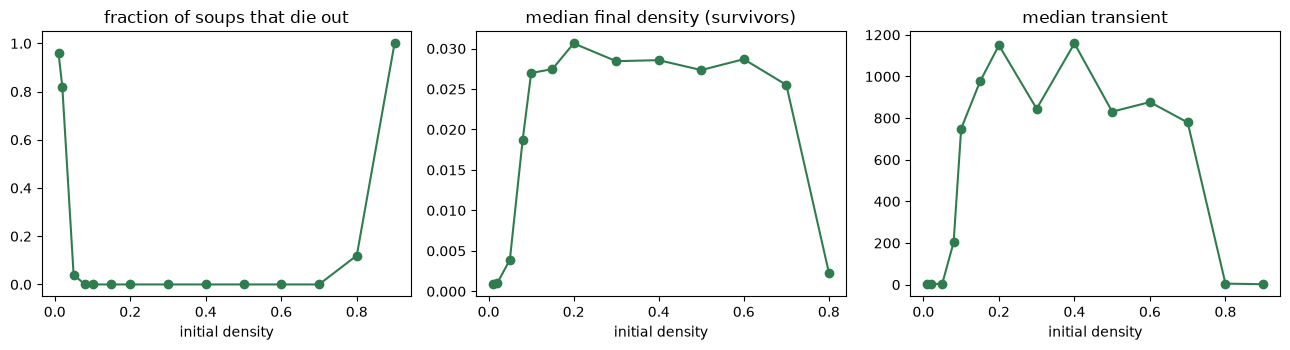

In [3]:
x = np.array(DENSITIES)
died = []
final = []
transient = []
for rho0 in DENSITIES:
    done = sweep[(sweep[:, 0] == rho0) & (sweep[:, 2] >= 0)]
    died.append(np.mean(done[:, 4] == 0))
    alive = done[done[:, 4] > 0]
    final.append(np.median(alive[:, 4]) if len(alive) else np.nan)
    transient.append(np.median(done[:, 2]))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, y, title in zip(
    axes,
    [died, final, transient],
    ["fraction of soups that die out", "median final density (survivors)", "median transient"],
    strict=True,
):
    ax.plot(x, y, "o-", color="#2f7d4f")
    ax.set_xlabel("initial density")
    ax.set_title(title)
fig.tight_layout()
fig.savefig(FIGURES / "exp02_density.png", dpi=150)
plt.show()

### Is there a fixed extinction threshold?

On the random network of experiment 3 the dividing line was 0.19 whatever the size. Here the same sparse densities are tried on grids of different size: 40 soups each, counted as surviving if any cell is still alive after 200 generations.

In [4]:
SURVIVAL_SIZES = [32, 64, 128, 256]
SPARSE = [0.01, 0.02, 0.03]
survival = []
for L in SURVIVAL_SIZES:
    for rho0 in SPARSE:
        alive = 0
        for seed in range(40):
            soup = np.random.default_rng([L, int(rho0 * 1000), seed]).random((L, L)) < rho0
            state = soup
            for _ in range(200):
                state = step(state, CONWAY, TORUS)
                if not state.any():
                    break
            alive += bool(state.any())
        survival.append((L, rho0, alive / 40))
survival = np.array(survival)
np.savetxt(
    DATA / "survival.csv",
    survival,
    delimiter=",",
    fmt="%.6g",
    header="L,start_density,fraction_alive_after_200",
    comments="",
)
print(f"{'L':>4} " + " ".join(f"{r:>8}" for r in SPARSE))
for L in SURVIVAL_SIZES:
    rows = survival[survival[:, 0] == L]
    print(f"{L:>4} " + " ".join(f"{v:>8.0%}" for v in rows[:, 2]))

   L     0.01     0.02     0.03
  32       5%       5%      20%
  64       0%      18%      65%
 128      15%      68%      98%
 256      20%     100%     100%


## 2b. Avalanches with open boundaries

Grids of side $L$ = 32, 64, 128 (5000 avalanches each) and 256 (3000). The outer two rows and columns are cleared after every step, so gliders that reach the edge leave the system. Start from a settled soup, then repeatedly: pick a random dead cell in the interior, make it alive, run until the grid is back on a cycle, record size, duration and the live density afterwards, continue from the new state.

The first 500 avalanches are treated as warm-up. If a grid runs empty, everything after that point is a lonely cell dying at once, so only avalanches before it are analysed.

In [5]:
N_AVALANCHES = {32: 5000, 64: 5000, 128: 5000, 256: 3000}
SIZES = list(N_AVALANCHES)
WARMUP = 500

records = []  # L, index, size, duration, censored, live density afterwards
for L, n in N_AVALANCHES.items():
    mask = open_border((L, L))
    interior = mask.sum()
    rng = np.random.default_rng(L)
    state = settle(rng.random((L, L)) < 0.35, CONWAY, OPEN, mask, MAX_STEPS)
    start = time.perf_counter()
    for i in range(n):
        dead = np.argwhere(~state & mask)
        cell = tuple(int(v) for v in dead[rng.integers(len(dead))])
        result = avalanche(state, cell, CONWAY, OPEN, mask, MAX_STEPS)
        censored = result.state is None
        density = -1.0 if censored else result.state.sum() / interior
        records.append((L, i, result.size, result.duration, int(censored), density))
        if censored:
            print(f"L = {L}: avalanche {i} hit the cap; stopping this size")
            break
        state = result.state
    print(
        f"L = {L:>3}: {i + 1} avalanches in {time.perf_counter() - start:.1f} s, "
        f"final live density {state.sum() / interior:.3f}"
    )

aval = np.array(records)
np.savetxt(
    DATA / "avalanches.csv",
    aval,
    fmt="%.6g",
    delimiter=",",
    header="L,index,size,duration,censored,density_after",
    comments="",
)


def usable(L):
    rows = aval[aval[:, 0] == L]
    empty = np.flatnonzero(rows[:, 5] == 0)
    stop = rows[empty[0], 1] if len(empty) else np.inf
    keep = (rows[:, 1] >= WARMUP) & (rows[:, 1] < stop) & (rows[:, 4] == 0)
    return rows[keep], stop

L =  32: 5000 avalanches in 1.8 s, final live density 0.000
L =  64: 5000 avalanches in 12.6 s, final live density 0.017
L = 128: 5000 avalanches in 83.0 s, final live density 0.030
L = 256: 3000 avalanches in 260.3 s, final live density 0.026


L = 32: the grid ran empty after avalanche 631


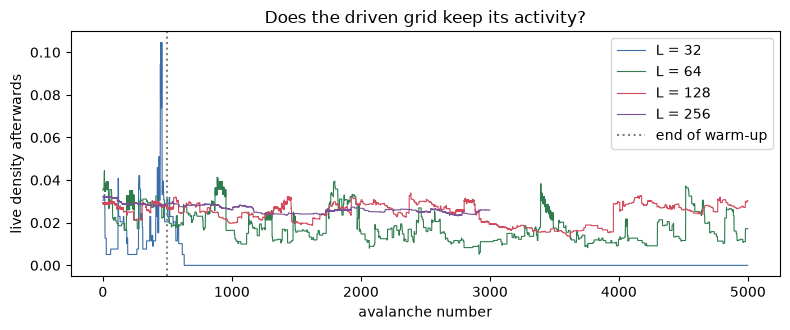

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
colors = {32: "#3b6ea8", 64: "#2f7d4f", 128: "#d1495b", 256: "#7a5195"}
for L in SIZES:
    rows = aval[aval[:, 0] == L]
    ax.plot(rows[:, 1], rows[:, 5], color=colors[L], lw=0.8, label=f"L = {L}")
    _, stop = usable(L)
    if np.isfinite(stop):
        print(f"L = {L}: the grid ran empty after avalanche {int(stop)}")
ax.axvline(WARMUP, color="grey", ls=":", label="end of warm-up")
ax.set_xlabel("avalanche number")
ax.set_ylabel("live density afterwards")
ax.set_title("Does the driven grid keep its activity?")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "exp02_drive_density.png", dpi=150)
plt.show()

In [7]:
def describe(values, label):
    fit = fit_power_law(values)
    verdict = "power law" if fit.loglik_ratio > 0 else "exponential"
    sure = "significant" if fit.p_value < 0.1 else "not significant"
    print(
        f"  {label:>8}: alpha = {fit.alpha:.2f} ± {fit.alpha_err:.2f}, xmin = {fit.xmin:>3}, "
        f"tail n = {fit.n_tail:>4}, KS = {fit.ks:.3f}, LR = {fit.loglik_ratio:+8.1f} "
        f"(p = {fit.p_value:.3f}) -> {verdict}, {sure}"
    )
    return fit


fits = {}
for L in SIZES:
    rows, _ = usable(L)
    interior = (L - 4) ** 2
    if len(rows) < 1000:
        print(f"L = {L}: only {len(rows)} usable avalanches before the grid ran empty; not fitted")
        continue
    sizes = rows[:, 2]
    print(
        f"L = {L}: {len(rows)} avalanches, median size {np.median(sizes):.0f}, "
        f"99th percentile {np.percentile(sizes, 99):.0f}, "
        f"max size {sizes.max():.0f} ({sizes.max() / interior:.0%} of the interior), "
        f"max duration {rows[:, 3].max():.0f}"
    )
    fits[L] = (describe(sizes, "size"), describe(rows[:, 3], "duration"))

L = 32: only 131 usable avalanches before the grid ran empty; not fitted
L = 64: 4500 avalanches, median size 1, 99th percentile 594, max size 3355 (93% of the interior), max duration 2225
      size: alpha = 2.48 ± 0.20, xmin = 518, tail n =   53, KS = 0.078, LR =     -0.2 (p = 0.952) -> exponential, not significant
  duration: alpha = 2.23 ± 0.15, xmin = 134, tail n =   64, KS = 0.085, LR =     +3.4 (p = 0.501) -> power law, not significant
L = 128: 4500 avalanches, median size 1, 99th percentile 1578, max size 10192 (66% of the interior), max duration 2971
      size: alpha = 1.59 ± 0.04, xmin =  64, tail n =  266, KS = 0.077, LR =   +143.0 (p = 0.000) -> power law, significant
  duration: alpha = 1.42 ± 0.02, xmin =   2, tail n =  613, KS = 0.077, LR =   +774.3 (p = 0.000) -> power law, significant
L = 256: 2500 avalanches, median size 1, 99th percentile 1857, max size 30189 (48% of the interior), max duration 7354
      size: alpha = 1.81 ± 0.11, xmin = 731, tail n =   55, KS = 0.

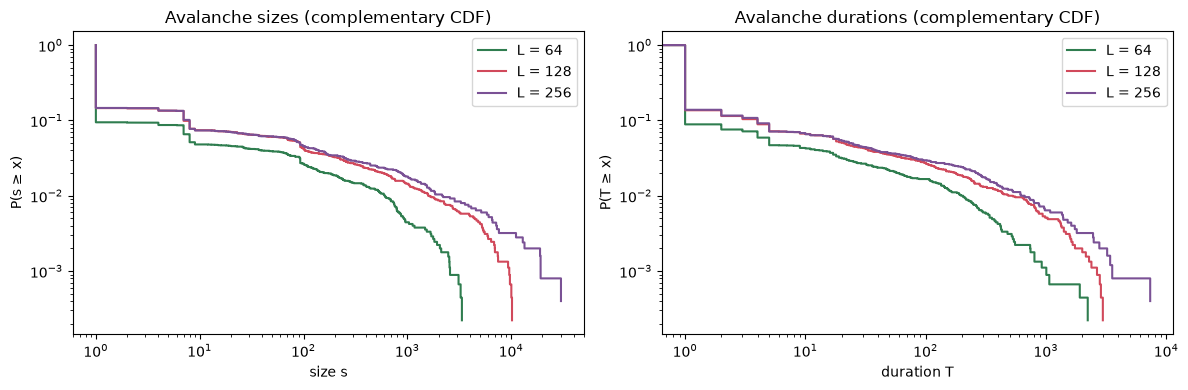

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, label in [(axes[0], 2, "size s"), (axes[1], 3, "duration T")]:
    for L in fits:
        rows, _ = usable(L)
        values = np.sort(rows[:, col])
        ccdf = 1.0 - np.arange(len(values)) / len(values)
        ax.loglog(values, ccdf, drawstyle="steps-post", color=colors[L], label=f"L = {L}")
    ax.set_xlabel(label)
    ax.set_ylabel(f"P({label.split()[-1]} ≥ x)")
    ax.legend()
axes[0].set_title("Avalanche sizes (complementary CDF)")
axes[1].set_title("Avalanche durations (complementary CDF)")
fig.tight_layout()
fig.savefig(FIGURES / "exp02_avalanches.png", dpi=150)
plt.show()

## 2c. Control: the same avalanches on a torus

$L$ = 64 torus, 2000 avalanches (first 500 as warm-up). Gliders cannot leave, so any glider released by an avalanche keeps circling.

In [9]:
rng = np.random.default_rng(640)
state = settle(rng.random((64, 64)) < 0.35, CONWAY, TORUS, None, MAX_STEPS)
torus_records = []
start = time.perf_counter()
for i in range(2000):
    dead = np.argwhere(~state)
    cell = tuple(int(v) for v in dead[rng.integers(len(dead))])
    result = avalanche(state, cell, CONWAY, TORUS, None, MAX_STEPS)
    torus_records.append((i, result.size, result.duration, int(result.state is None)))
    if result.state is None:
        print(f"avalanche {i} hit the cap; stopping")
        break
    state = result.state
print(f"{len(torus_records)} torus avalanches in {time.perf_counter() - start:.1f} s")
torus = np.array(torus_records)
np.savetxt(
    DATA / "avalanches_torus.csv",
    torus,
    fmt="%d",
    delimiter=",",
    header="index,size,duration,censored",
    comments="",
)

rows = torus[(torus[:, 0] >= WARMUP) & (torus[:, 3] == 0)]
print(
    f"torus L = 64: median size {np.median(rows[:, 1]):.0f}, max size {rows[:, 1].max()}, "
    f"max duration {rows[:, 2].max()}"
)
describe(rows[:, 1], "size")
describe(rows[:, 2], "duration")
final_cycle = detect_cycle(state, CONWAY, TORUS, MAX_STEPS)
print(f"period of the final torus state: {final_cycle.period}")

2000 torus avalanches in 13.6 s
torus L = 64: median size 1, max size 4096, max duration 4418
      size: alpha = 1.56 ± 0.06, xmin =  57, tail n =   89, KS = 0.122, LR =    +29.7 (p = 0.003) -> power law, significant
  duration: alpha = 1.43 ± 0.03, xmin =   2, tail n =  212, KS = 0.098, LR =   +304.5 (p = 0.000) -> power law, significant
period of the final torus state: 2


## Results vs. predictions

| # | Prediction | Result |
|---|---|---|
| 1 | final density roughly constant for 0.2–0.6 | **Correct**: 0.027–0.031 across 0.1–0.7. |
| 2 | threshold lower than 0.19, about 0.1 | Right direction, too high: on 64 × 64 the line is near 0.03. More importantly, there is no fixed line at all (puzzle A). |
| 3 | still state at 0.8 and 0.9 | Still, but empty: at 0.9 every soup dies within three generations (puzzle B). |
| 4 | longest transients at 0.1 | Slightly off: transients form a broad plateau from 0.15 to 0.7 (median about 800–1150). |
| 5 | straight line on log–log axes | Holds at $L$ = 128: above size 64 a power law fits far better than an exponential. |
| 6 | slope about −1 | Steeper: $\alpha \approx$ 1.6 at $L$ = 128 and on the torus. |
| 7 | the largest avalanche levels off | Half right: the single largest avalanche keeps growing with the grid, but the 99th percentile barely moves from $L$ = 128 to 256 (1578 → 1857) while the area grows fourfold. |
| 8 | Life is self-organized critical | **Probably not** (tentative). See puzzle E. |

## Puzzles

The data did a few things that were not obvious in advance. Try each one before opening the answer.

**A. On the random network soups below density 0.19 died out; on the lattice they survive down to about 0.03, and the bigger the grid, the lower they survive.**
*Hint: how many stable objects does a grid need to stay alive?*

<details><summary>Answer</summary>

One. A grid stays alive if a single stable object (a block, say) forms anywhere. More area means more independent chances for that, so the probability of survival grows with the grid at any fixed density, and there is no fixed threshold: at density 0.02, 5 % of 32 × 32 grids survive and 100 % of 256 × 256 grids. The mean-field argument behind 0.19 averages space away and cannot see that a few clustered cells can sustain each other locally.
</details>

**B. At starting density 0.9 every soup is dead within three generations.**
*Hint: what does a live cell surrounded by live cells do?*

<details><summary>Answer</summary>

Overcrowding. Almost every live cell has more than three live neighbours and dies; the few dead cells are surrounded by live ones and almost never have *exactly* three. On a 64 × 64 grid fewer than one birth is expected in the first step, so the grid empties at once.
</details>

**C. The median avalanche has size 1: most added cells change nothing.**
*Hint: where does a randomly placed cell usually land?*

<details><summary>Answer</summary>

The settled grid is about 97 % empty. A random new cell usually lands with fewer than two live neighbours and dies at the next step; the only difference ever was the cell itself. This happened for 85 % (at $L$ = 128) to 99 % (at $L$ = 32) of the added cells.
</details>

**D. The 32 × 32 grid ran empty after 631 avalanches and never recovered.**
*Hint: what happens when one cell is added to an empty grid? And what do open boundaries take away?*

<details><summary>Answer</summary>

Avalanches release gliders, and with open boundaries the gliders carry live cells out of the system; a small grid loses its debris faster than single added cells can rebuild it. The empty grid is an **absorbing state**: a lone cell added to it dies at once, so the grid can never leave it. A sandpile always keeps its sand between avalanches; Life does not, which is a first reason to doubt that it organizes itself into a critical state.
</details>

**E. Is the heavy tail critical, or just wide?**
*Hint: if avalanches have no typical size, how should the large ones change when the grid area grows fourfold?*

<details><summary>Answer (tentative)</summary>

For a critical system the cut-off of the distribution should move out with the system size, and the exponent should stay the same. Here the 99th percentile grows from 594 to 1578 (64 → 128) but only to 1857 (128 → 256), while the fitted exponent moves from 1.59 to 1.81. The largest single avalanche keeps growing, so the tail is wide, but large avalanches seem to have a typical scale of a couple of thousand cells. That points to *not critical*, in line with Bennett and Bourzutschky (1991) and against the original claim of Bak, Chen and Creutz (1989). The tail at $L$ = 256 contains only 55 avalanches, so the conclusion is tentative.
</details>

## Conclusions

- **The initial density matters only at the extremes.** Between about 0.1 and 0.7 random soups settle to the same sparse ash of about 3 % live cells.
- **Extinction on a lattice is a finite-size effect.** Survival needs only one stable object anywhere, so larger grids survive from lower densities. The mean-field threshold of experiment 3 does not carry over to the lattice.
- **Avalanches have a heavy tail but probably no criticality.** At one grid size the distribution looks like a power law with $\alpha \approx 1.6$; across sizes the typical large avalanche stops growing, and small grids can drain to the empty absorbing state. Checking several system sizes, not one log–log plot, decides the question.

Limitations and open questions: see the [write-up](../docs/experiments/02-criticality.md).